# Results for UORED-VAFCLS, PU and CWRU datasets

In folder `data/saved_logits` there are logits for the best models obtained in each dataset using the proposed 3:2 split. This notebook will show **ROC curves + Macro AUC** for all datasets.

In [1]:
# open the file and load the logits
import torch
import autorootcwd
import pandas as pd
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
logits_folder = "data/saved_logits"

In [3]:
def fpr_score(fprs, tprs):
    """
    Compute the false positive rate (FPR) score for a binary classification model.

    Notes
    -----
    The FPR score is computed as the false positive rate of the model. The false positive rate is the
    proportion of negative samples that are incorrectly classified as positive. The FPR score is
    used to optimize the model by maximizing the true negative rate (TNR), which is equivalent to
    minimizing the false alarm rate.

    """

    desired_tpr = 0.9
    desired_tpr_idx = np.abs(tprs - desired_tpr).argmin()
    fpr_desired = fprs[desired_tpr_idx]

    return fpr_desired

In [4]:
### Process logits into dataframe

def logits_to_df(logits, fault_modes = ["inner", "outer", "ball", "cage"]):

    cols = ["idx"] + [f"logit_{fm}" for fm in fault_modes] + fault_modes
    logits_df = pd.DataFrame(logits.cpu().numpy(),
                         columns=cols)
    # cast all as int
    logits_df[fault_modes] = logits_df[fault_modes].astype(int)
    # apply torch sigmoid to the logit columns and create new columns with the results
    for fault in fault_modes:
        logits_df[f'prob_{fault}'] = torch.sigmoid(torch.tensor(logits_df[f'logit_{fault}'].values)).numpy()
    return logits_df

In [5]:

def vertical_average(fpr, tpr, start_at_zero=True, points=1000):
    """Compute vertical average ROC curve and ROC area"""
    fpr_grid = np.linspace(0.0, 1.0, points)

    if start_at_zero:
        iterable = range(len(fpr))
    else:
        iterable = range(1, len(fpr) + 1)

    tprs = []
    for i in iterable:
        tpr_interp = np.interp(fpr_grid, fpr[i], tpr[i])
        tprs.append(tpr_interp)

    tprs = np.array(tprs)
    mean_tpr = tprs.mean(axis=0)
    std_tpr = tprs.std(axis=0)
    auroc = auc(fpr_grid, mean_tpr)

    return fpr_grid, mean_tpr, std_tpr, tprs

def horizontal_average(fpr, tpr, start_at_zero=True, points=1000):
    """Compute horizontal average ROC curve and ROC area"""
    tpr_grid = np.linspace(0.0, 1.0, points)

    if start_at_zero:
        iterable = range(len(tpr))
    else:
        iterable = range(1, len(tpr) + 1)

    fprs = []
    for i in iterable:
        fpr_interp = np.interp(tpr_grid, tpr[i], fpr[i])
        #fpr_interp = np.interp(tpr[i], fpr[i], tpr_grid)
        fprs.append(fpr_interp)

    fprs = np.array(fprs)
    mean_fpr = fprs.mean(axis=0)
    std_fpr = fprs.std(axis=0)
    auroc = auc(mean_fpr, tpr_grid)

    return mean_fpr, tpr_grid, std_fpr, fprs

## 1. UORED-VAFCLS

In [6]:
### Ottawa ROC curves for all runs
outer_curves = []
ball_curves = []
cage_curves = []
inner_curves = []

for split in range (5, 105):
    path = f"{logits_folder}/ottawa/ottawa_eval_RCRG_fft_norm_none_std_0.3_lr_0.001_bs_256_run_{split}/test/epoch_30_run_0.pt"
    logits = torch.load(path)
    logits_df = logits_to_df(logits)
    
    roc_inner = roc_curve(logits_df['inner'].values, logits_df['prob_inner'].values)
    inner_curves.append(roc_inner)
    roc_outer = roc_curve(logits_df['outer'].values, logits_df['prob_outer'].values)
    outer_curves.append(roc_outer)
    roc_ball = roc_curve(logits_df['ball'].values, logits_df['prob_ball'].values   )
    ball_curves.append(roc_ball)
    roc_cage = roc_curve(logits_df['cage'].values, logits_df['prob_cage'].values)
    cage_curves.append(roc_cage)

In [7]:
roc_inner = [(x[0], x[1]) for x in inner_curves]
roc_outer = [(x[0], x[1]) for x in outer_curves]
roc_ball = [(x[0], x[1]) for x in ball_curves]
roc_cage = [(x[0], x[1]) for x in cage_curves]

In [8]:
fprs_inner, tprs_inner = zip(*roc_inner)
fprs_outer, tprs_outer = zip(*roc_outer)
fprs_ball, tprs_ball = zip(*roc_ball)
fprs_cage, tprs_cage = zip(*roc_cage)


mean_fpr_inner, tpr_grid, std_fpr_inner, _ = horizontal_average(fprs_inner, tprs_inner, points=10000)

aucs_inner = pd.Series([auc(curve[0], curve[1]) for curve in inner_curves]).values.reshape(1,100)
inner_aucs_mean = aucs_inner.mean()
inner_aucs_std = aucs_inner.std()

mean_fpr_outer, tpr_grid, std_fpr_outer, _ = horizontal_average(fprs_outer, tprs_outer, points=10000)

aucs_outer = pd.Series([auc(curve[0], curve[1]) for curve in outer_curves]).values.reshape(1,100)
outer_aucs_mean = aucs_outer.mean()
outer_aucs_std = aucs_outer.std()

mean_fpr_ball, tpr_grid, std_fpr_ball, _ = horizontal_average(fprs_ball, tprs_ball, points=10000)

aucs_ball = pd.Series([auc(curve[0], curve[1]) for curve in ball_curves]).values.reshape(1,100)
ball_aucs_mean = aucs_ball.mean()
ball_aucs_std = aucs_ball.std()

mean_fpr_cage, tpr_grid, std_fpr_cage, _ = horizontal_average(fprs_cage, tprs_cage, points=10000)

aucs_cage = pd.Series([auc(curve[0], curve[1]) for curve in cage_curves]).values.reshape(1,100)
cage_aucs_mean = aucs_cage.mean()
cage_aucs_std = aucs_cage.std()

aucs = np.concatenate([aucs_inner, aucs_outer, aucs_ball, aucs_cage], axis=0)
AUC_MEAN = aucs.mean(axis=0).mean()
AUC_STD = aucs.mean(axis=0).std()

fprs = [mean_fpr_inner, mean_fpr_outer, mean_fpr_ball, mean_fpr_cage]
scores = []
for fpr in fprs:
    score = fpr_score(fpr, tpr_grid)
    scores.append(score)

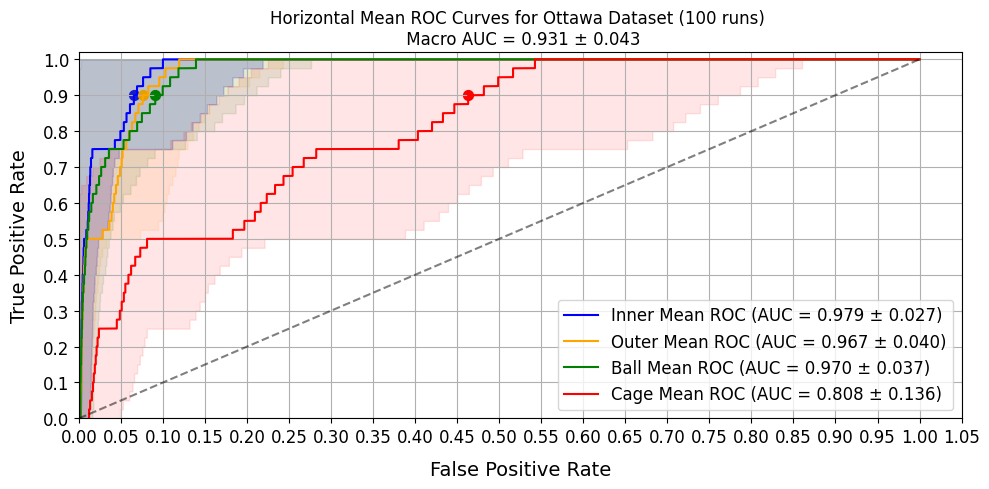

In [9]:
plt.figure(figsize=(10, 5))
plt.plot(mean_fpr_inner,tpr_grid, label='Inner Mean ROC (AUC = {:.3f} ± {:.3f})'.format(inner_aucs_mean, inner_aucs_std), color='blue')
plt.fill_betweenx(tpr_grid, 
                 mean_fpr_inner - std_fpr_inner, 
                 mean_fpr_inner + std_fpr_inner, 
                 color='blue', alpha=0.2)
plt.scatter( scores[0], 0.9, color='blue', s=50, marker='o')

plt.plot( mean_fpr_outer, tpr_grid, label='Outer Mean ROC (AUC = {:.3f} ± {:.3f})'.format(outer_aucs_mean, outer_aucs_std), color='orange')
plt.fill_betweenx(tpr_grid, 
                 mean_fpr_outer - std_fpr_outer, 
                 mean_fpr_outer + std_fpr_outer, 
                 color='orange', alpha=0.1)
plt.scatter( scores[1], 0.9, color='orange', s=50, marker='o')

plt.plot( mean_fpr_ball, tpr_grid, label='Ball Mean ROC (AUC = {:.3f} ± {:.3f})'.format(ball_aucs_mean, ball_aucs_std), color='green')
plt.fill_betweenx(tpr_grid, 
                 mean_fpr_ball - std_fpr_ball, 
                 mean_fpr_ball + std_fpr_ball, 
                 color='green', alpha=0.1)
plt.scatter( scores[2], 0.9, color='green', s=50, marker='o')

plt.plot( mean_fpr_cage, tpr_grid, label='Cage Mean ROC (AUC = {:.3f} ± {:.3f})'.format(cage_aucs_mean, cage_aucs_std), color='red')
plt.fill_betweenx(tpr_grid, 
                 mean_fpr_cage - std_fpr_cage, 
                 mean_fpr_cage + std_fpr_cage, 
                 color='red', alpha=0.1)
plt.scatter( scores[3], 0.9, color='red', s=50, marker='o')

plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
plt.xlabel('False Positive Rate', fontsize=14, labelpad=10)
plt.ylabel('True Positive Rate', fontsize=14, labelpad=10)
plt.title(f'Horizontal Mean ROC Curves for Ottawa Dataset (100 runs) \n Macro AUC = {AUC_MEAN:.3f} ± {AUC_STD:.3f}')
plt.grid()
plt.legend(fontsize="large")
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.02])
plt.yticks(np.arange(0.0, 1.1, 0.1))
plt.xticks(np.arange(0.0, 1.1, 0.05))
# save as pdf with 300dpi
plt.tight_layout()
#plt.savefig('notebooks/ottawa/ottawa_mean_roc_curves_horizontal.pdf', dpi=600, bbox_inches='tight')
plt.show()

In [17]:
(979 + 967 + 970 + 808) / 4000

0.931

In [10]:
for fpr in fprs:
    score = fpr_score(fpr, tpr_grid)
    fault = "Inner" if np.array_equal(fpr, mean_fpr_inner) else "Outer" if np.array_equal(fpr, mean_fpr_outer) else "Ball" if np.array_equal(fpr, mean_fpr_ball) else "Cage"
    print("FPR score at TPR=0.9 for {}: {:.4f}".format(fault, score))

FPR score at TPR=0.9 for Inner: 0.0653
FPR score at TPR=0.9 for Outer: 0.0759
FPR score at TPR=0.9 for Ball: 0.0908
FPR score at TPR=0.9 for Cage: 0.4630


## 2. Paderborn

In [10]:
### PU ROC curves for all runs
outer_curves = []
inner_curves = []

for split in range (5, 105):
    path = f"{logits_folder}/pu/paderborn_eval_envelope_lr_0.001_bs_32_norm_global_run_{split}/test/epoch_30_run_0.pt"
    logits = torch.load(path)
    logits_df = logits_to_df(logits, fault_modes=["inner", "outer"])
    
    roc_inner = roc_curve(logits_df['inner'].values, logits_df['prob_inner'].values)
    inner_curves.append(roc_inner)
    roc_outer = roc_curve(logits_df['outer'].values, logits_df['prob_outer'].values)
    outer_curves.append(roc_outer)

In [11]:
roc_inner = [(x[0], x[1]) for x in inner_curves]
roc_outer = [(x[0], x[1]) for x in outer_curves]

In [12]:
fprs_inner, tprs_inner = zip(*roc_inner)
fprs_outer, tprs_outer = zip(*roc_outer)

mean_fpr_inner, tpr_grid, std_fpr_inner, _ = horizontal_average(fprs_inner, tprs_inner, points=10000)

aucs_inner = pd.Series([auc(curve[0], curve[1]) for curve in inner_curves]).values.reshape(1,100)
inner_aucs_mean = aucs_inner.mean()
inner_aucs_std = aucs_inner.std()

mean_fpr_outer, tpr_grid, std_fpr_outer, _ = horizontal_average(fprs_outer, tprs_outer, points=10000)
aucs_outer = pd.Series([auc(curve[0], curve[1]) for curve in outer_curves]).values.reshape(1,100)
outer_aucs_mean = aucs_outer.mean()
outer_aucs_std = aucs_outer.std()


aucs = np.concatenate([aucs_inner, aucs_outer], axis=0)
AUC_MEAN = aucs.mean(axis=0).mean()
AUC_STD = aucs.mean(axis=0).std()

fprs = [mean_fpr_inner, mean_fpr_outer]
scores = []
for fpr in fprs:
    score = fpr_score(fpr, tpr_grid)
    scores.append(score)

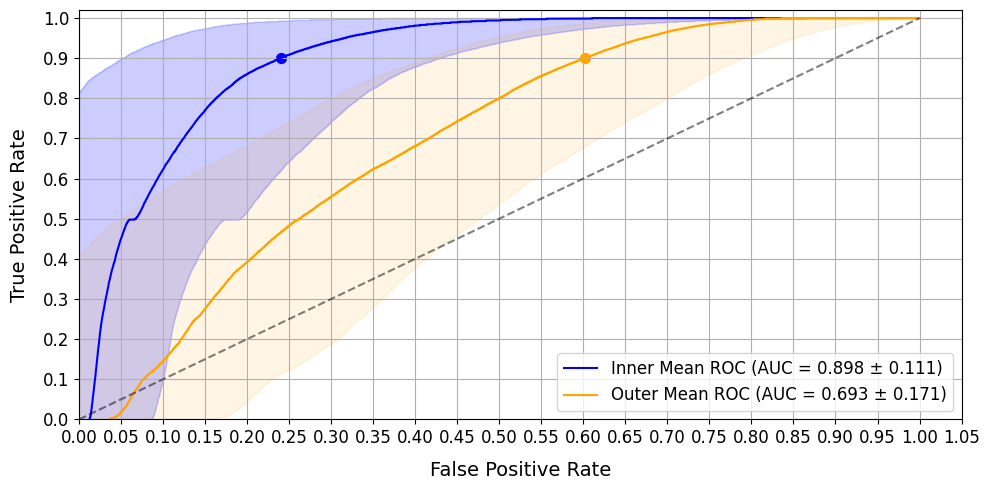

In [13]:
plt.figure(figsize=(10, 5))
plt.plot(mean_fpr_inner,tpr_grid, label='Inner Mean ROC (AUC = {:.3f} ± {:.3f})'.format(inner_aucs_mean, inner_aucs_std), color='blue')
plt.fill_betweenx(tpr_grid, 
                 mean_fpr_inner - std_fpr_inner, 
                 mean_fpr_inner + std_fpr_inner, 
                 color='blue', alpha=0.2)
plt.scatter( scores[0], 0.9, color='blue', s=50, marker='o')

plt.plot( mean_fpr_outer, tpr_grid, label='Outer Mean ROC (AUC = {:.3f} ± {:.3f})'.format(outer_aucs_mean, outer_aucs_std), color='orange')
plt.fill_betweenx(tpr_grid, 
                 mean_fpr_outer - std_fpr_outer, 
                 mean_fpr_outer + std_fpr_outer, 
                 color='orange', alpha=0.1)
plt.scatter( scores[1], 0.9, color='orange', s=50, marker='o')

plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
plt.xlabel('False Positive Rate', fontsize=14, labelpad=10)
plt.ylabel('True Positive Rate', fontsize=14, labelpad=10)
#plt.title(f'Horizontal Mean ROC Curves for PU Dataset (100 runs) \n Macro AUC = {AUC_MEAN:.3f} ± {AUC_STD:.3f}')
plt.grid()
plt.legend(fontsize="large")
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.02])
plt.yticks(np.arange(0.0, 1.1, 0.1))
plt.xticks(np.arange(0.0, 1.1, 0.05))
# save as pdf with 300dpi
plt.tight_layout()
plt.savefig('notebooks/paderborn/pu_mean_roc_curves_horizontal.pdf', dpi=600, bbox_inches='tight')
plt.show()

In [42]:
for fpr in fprs:
    score = fpr_score(fpr, tpr_grid)
    fault = "Inner" if np.array_equal(fpr, mean_fpr_inner) else "Outer" if np.array_equal(fpr, mean_fpr_outer) else "Ball" if np.array_equal(fpr, mean_fpr_ball) else "Cage"
    print("FPR score at TPR=0.9 for {}: {:.4f}".format(fault, score))

FPR score at TPR=0.9 for Inner: 0.2400
FPR score at TPR=0.9 for Outer: 0.6015


# CWRU

In [6]:
all_preds = "data/saved_logits/cwru/preds.npy"
preds = np.load(all_preds)

In [7]:
inner_curves = []
outer_curves = []
ball_curves = []

for row in preds:

    roc_inner = roc_curve(row[4], row[1])
    inner_curves.append(roc_inner)
    roc_outer = roc_curve(row[3], row[0])
    outer_curves.append(roc_outer)
    roc_ball = roc_curve(row[5],row[2])
    ball_curves.append(roc_ball)

In [8]:
roc_inner = [(x[0], x[1]) for x in inner_curves]
roc_outer = [(x[0], x[1]) for x in outer_curves]
roc_ball = [(x[0], x[1]) for x in ball_curves]

In [9]:
fprs_inner, tprs_inner = zip(*roc_inner)
fprs_outer, tprs_outer = zip(*roc_outer)
fprs_ball, tprs_ball = zip(*roc_ball)

mean_fpr_inner, tpr_grid, std_fpr_inner, _ = horizontal_average(fprs_inner, tprs_inner, points=10000)

aucs_inner = pd.Series([auc(curve[0], curve[1]) for curve in inner_curves]).values.reshape(1,100)
inner_aucs_mean = aucs_inner.mean()
inner_aucs_std = aucs_inner.std()

mean_fpr_outer, tpr_grid, std_fpr_outer, _ = horizontal_average(fprs_outer, tprs_outer, points=10000)

aucs_outer = pd.Series([auc(curve[0], curve[1]) for curve in outer_curves]).values.reshape(1,100)
outer_aucs_mean = aucs_outer.mean()
outer_aucs_std = aucs_outer.std()

mean_fpr_ball, tpr_grid, std_fpr_ball, _ = horizontal_average(fprs_ball, tprs_ball, points=10000)

aucs_ball = pd.Series([auc(curve[0], curve[1]) for curve in ball_curves]).values.reshape(1,100)
ball_aucs_mean = aucs_ball.mean()
ball_aucs_std = aucs_ball.std()

aucs= np.concatenate([aucs_inner, aucs_outer, aucs_ball], axis=0)
AUC_MEAN = aucs.mean(axis=0).mean()
AUC_STD = aucs.mean(axis=0).std()

fprs = [mean_fpr_inner, mean_fpr_outer, mean_fpr_ball]
scores = []
for fpr in fprs:
    score = fpr_score(fpr, tpr_grid)
    scores.append(score)

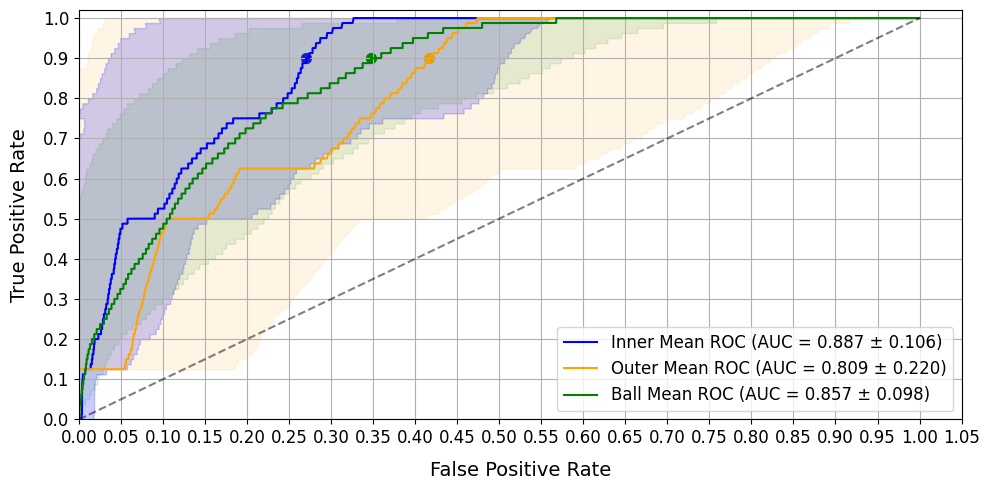

In [10]:
plt.figure(figsize=(10, 5))
plt.plot(mean_fpr_inner,tpr_grid, label='Inner Mean ROC (AUC = {:.3f} ± {:.3f})'.format(inner_aucs_mean, inner_aucs_std), color='blue')
plt.fill_betweenx(tpr_grid, 
                 mean_fpr_inner - std_fpr_inner, 
                 mean_fpr_inner + std_fpr_inner, 
                 color='blue', alpha=0.2)
plt.scatter( scores[0], 0.9, color='blue', s=50, marker='o')

plt.plot( mean_fpr_outer, tpr_grid, label='Outer Mean ROC (AUC = {:.3f} ± {:.3f})'.format(outer_aucs_mean, outer_aucs_std), color='orange')
plt.fill_betweenx(tpr_grid, 
                 mean_fpr_outer - std_fpr_outer, 
                 mean_fpr_outer + std_fpr_outer, 
                 color='orange', alpha=0.1)
plt.scatter( scores[1], 0.9, color='orange', s=50, marker='o')

plt.plot( mean_fpr_ball, tpr_grid, label='Ball Mean ROC (AUC = {:.3f} ± {:.3f})'.format(ball_aucs_mean, ball_aucs_std), color='green')
plt.fill_betweenx(tpr_grid, 
                 mean_fpr_ball - std_fpr_ball, 
                 mean_fpr_ball + std_fpr_ball, 
                 color='green', alpha=0.1)
plt.scatter( scores[2], 0.9, color='green', s=50, marker='o')

plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
plt.xlabel('False Positive Rate', fontsize=14, labelpad=10)
plt.ylabel('True Positive Rate', fontsize=14, labelpad=10)
#plt.title(f'Horizontal Mean ROC Curves for CWRU Dataset (100 runs) \n Macro AUC = {AUC_MEAN:.3f} ± {AUC_STD:.3f}')
plt.grid()
plt.legend(fontsize="large")
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.02])
plt.yticks(np.arange(0.0, 1.1, 0.1))
plt.xticks(np.arange(0.0, 1.1, 0.05))
# save as pdf with 300dpi
plt.tight_layout()
plt.savefig('notebooks/cwru/cwru_mean_roc_curves_horizontal.pdf', dpi=600, bbox_inches='tight')
plt.show()

In [11]:
for fpr in fprs:
    score = fpr_score(fpr, tpr_grid)
    fault = "Inner" if np.array_equal(fpr, mean_fpr_inner) else "Outer" if np.array_equal(fpr, mean_fpr_outer) else "Ball" if np.array_equal(fpr, mean_fpr_ball) else "Cage"
    print("FPR score at TPR=0.9 for {}: {:.4f}".format(fault, score))

FPR score at TPR=0.9 for Inner: 0.2702
FPR score at TPR=0.9 for Outer: 0.4169
FPR score at TPR=0.9 for Ball: 0.3476
